1.
<p>Load 'bike_listings_s6.csv' in a new notebook 'bike_outliers.ipynb', then with `np.random.seed(7)` multiply 10 random price_inr values by 6 and set 6 random km_driven values to 400000. Draw a pandas `boxplot` for both columns and print how many rows the IQR rule (1.5 x IQR) and a z-score above 3 each flag. Hint: Missed Session 6? Build any 400-row bike table and fill blanks with medians. Constraint: No SciPy; use `mean()` and `std()`.</p>
2.
<p>Treat the outliers in three new columns: `price_capped` using `clip()` with the IQR fences (capping and flooring), `price_wins` clipped at the 5th and 95th percentiles from `quantile()`, and `km_log` using `np.log1p`. Print the max and mean of each original and treated column in one table. Constraint: Do not drop any rows and do not use SciPy's `winsorize`.</p>
3.
<p>Convert types in a copy named `bikes_typed`: rewrite price_inr as text like 'Rs 45,000', turn it back into numbers with `str.replace()` and `pd.to_numeric(errors='coerce')`, set brand and city to `category`, owner_count to `int8`, and add `is_first_owner` as a real bool from owner_count == 1. Print `dtypes` and total `memory_usage(deep=True)` before and after.</p>
4.
<p>Create `listed_on` with random 2024 dates (seed 7), written as 'DD/MM/YYYY' for 60% of rows and 'DD-Mon-YYYY' (like 05-Mar-2024) for the rest. Parse both into one datetime column with `pd.to_datetime` and `errors='coerce'`, confirm zero NaT, add `listed_month`, and save 'bike_listings_s7.csv'. Run Restart & Run All and push to 's07_bike_outliers' in your GitHub repo 'ds_analysis_portfolio'. Hint: Parse each format with its own `format=` and combine with `fillna`.</p>

In [6]:
import numpy as np
import pandas as pd

bikes = pd.read_csv("bike_listings_s6.csv")

print(bikes.head())
print("Shape:", bikes.shape)

   listing_id    brand      city  model_year  km_driven  owner_count  \
0         358   Tarang  Vadodara        2008    27522.0          2.0   
1         356   Sundar     Surat        2008    13485.0          3.0   
2         350   Sundar     Surat        2008    40258.0          3.0   
3         342   Tarang     Surat        2008    61676.0          1.0   
4          66  Rajhans  Vadodara        2008    28069.0          1.0   

   price_inr  
0    51958.0  
1   102539.0  
2    90128.0  
3    50963.0  
4    50963.0  
Shape: (400, 7)


In [7]:
np.random.seed(7)

# Select 10 random rows for price outliers
price_rows = np.random.choice(bikes.index, size=10, replace=False)

# Multiply their prices by 6
bikes.loc[price_rows, "price_inr"] = (
    bikes.loc[price_rows, "price_inr"] * 6
)

# Select 6 random rows for km outliers
km_rows = np.random.choice(bikes.index, size=6, replace=False)

# Set km driven to 400000
bikes.loc[km_rows, "km_driven"] = 400000

print("Price outliers added:", len(price_rows))
print("KM outliers added:", len(km_rows))

Price outliers added: 10
KM outliers added: 6


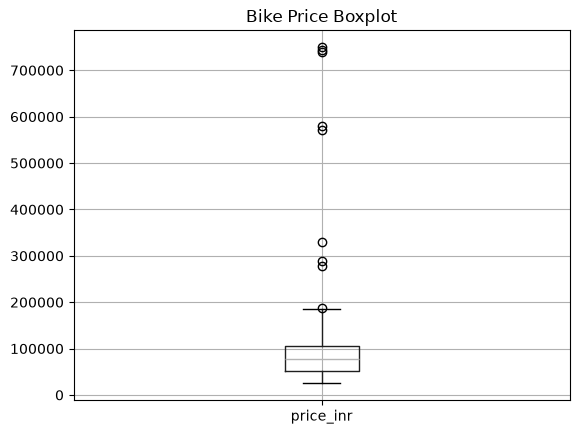

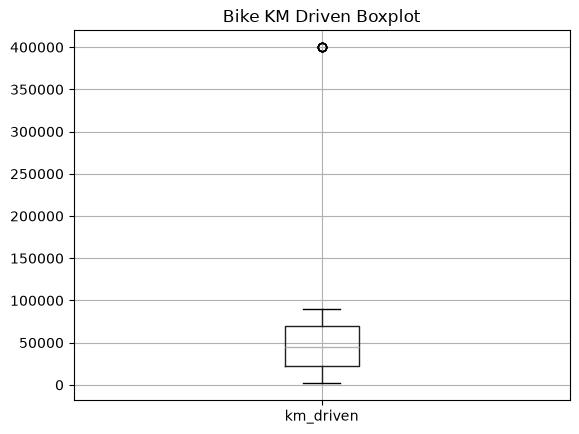

In [9]:
import matplotlib.pyplot as plt

# Price boxplot
bikes.boxplot(column="price_inr")
plt.title("Bike Price Boxplot")
plt.show()

# KM boxplot
bikes.boxplot(column="km_driven")
plt.title("Bike KM Driven Boxplot")
plt.show()

In [10]:
# Function to count IQR outliers
def iqr_outliers(data, column):
    q1 = data[column].quantile(0.25)
    q3 = data[column].quantile(0.75)

    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = (
        (data[column] < lower) |
        (data[column] > upper)
    ).sum()

    return count, lower, upper


price_iqr, price_lower, price_upper = iqr_outliers(
    bikes, "price_inr"
)

km_iqr, km_lower, km_upper = iqr_outliers(
    bikes, "km_driven"
)

print("Price IQR outliers:", price_iqr)
print("KM IQR outliers:", km_iqr)

Price IQR outliers: 9
KM IQR outliers: 6


In [11]:
# Calculate price z-score
price_z = (
    (bikes["price_inr"] - bikes["price_inr"].mean())
    / bikes["price_inr"].std()
)

# Calculate km z-score
km_z = (
    (bikes["km_driven"] - bikes["km_driven"].mean())
    / bikes["km_driven"].std()
)

# Count z-score outliers
price_z_count = (price_z.abs() > 3).sum()

km_z_count = (km_z.abs() > 3).sum()

print("Price z-score outliers:", price_z_count)
print("KM z-score outliers:", km_z_count)

Price z-score outliers: 6
KM z-score outliers: 6


In [12]:
outlier_report = pd.DataFrame({
    "Column": ["price_inr", "km_driven"],
    "IQR Outliers": [price_iqr, km_iqr],
    "Z Score Outliers": [price_z_count, km_z_count]
})

print(outlier_report)

      Column  IQR Outliers  Z Score Outliers
0  price_inr             9                 6
1  km_driven             6                 6


In [13]:
# Create treated columns
bikes["price_capped"] = bikes["price_inr"].clip(
    lower=price_lower,
    upper=price_upper
)

# Find 5th and 95th percentile
price_5 = bikes["price_inr"].quantile(0.05)
price_95 = bikes["price_inr"].quantile(0.95)

# Winsor-style clipping
bikes["price_wins"] = bikes["price_inr"].clip(
    lower=price_5,
    upper=price_95
)

# Log transformation
bikes["km_log"] = np.log1p(bikes["km_driven"])

print(bikes.head())

   listing_id    brand      city  model_year  km_driven  owner_count  \
0         358   Tarang  Vadodara        2008    27522.0          2.0   
1         356   Sundar     Surat        2008    13485.0          3.0   
2         350   Sundar     Surat        2008    40258.0          3.0   
3         342   Tarang     Surat        2008    61676.0          1.0   
4          66  Rajhans  Vadodara        2008    28069.0          1.0   

   price_inr  price_capped  price_wins     km_log  
0    51958.0       51958.0     51958.0  10.222777  
1   102539.0      102539.0    102539.0   9.509407  
2    90128.0       90128.0     90128.0  10.603089  
3    50963.0       50963.0     50963.0  11.029666  
4    50963.0       50963.0     50963.0  10.242457  


In [14]:
comparison = pd.DataFrame({
    "Column": [
        "price_inr",
        "price_capped",
        "price_wins",
        "km_driven",
        "km_log"
    ],

    "Maximum": [
        bikes["price_inr"].max(),
        bikes["price_capped"].max(),
        bikes["price_wins"].max(),
        bikes["km_driven"].max(),
        bikes["km_log"].max()
    ],

    "Mean": [
        bikes["price_inr"].mean(),
        bikes["price_capped"].mean(),
        bikes["price_wins"].mean(),
        bikes["km_driven"].mean(),
        bikes["km_log"].mean()
    ]
})

print(comparison)

         Column        Maximum          Mean
0     price_inr  749916.000000  88129.710000
1  price_capped  186314.375000  81152.018437
2    price_wins  131626.800000  79868.845000
3     km_driven  400000.000000  51053.322500
4        km_log      12.899222     10.492936


In [17]:
""" Task 3
"""
print("Original Data Types:")
print(bikes.dtypes)

before_memory = bikes.memory_usage(deep=True).sum()

print("\nOriginal Memory Usage:")
print(before_memory, "bytes")



Original Data Types:
listing_id        int64
brand               str
city                str
model_year        int64
km_driven       float64
owner_count     float64
price_inr       float64
price_capped    float64
price_wins      float64
km_log          float64
dtype: object

Original Memory Usage:
70195 bytes


In [18]:
bikes_typed = bikes.copy()

bikes_typed["price_inr"] = bikes_typed["price_inr"].apply(
    lambda x: f"Rs {x:,.0f}"
)

print("Price as text:")
print(bikes_typed["price_inr"].head())

bikes_typed["price_inr"] = pd.to_numeric(
    bikes_typed["price_inr"]
    .str.replace("Rs ", "", regex=False)
    .str.replace(",", "", regex=False),
    errors="coerce"
)

bikes_typed["brand"] = bikes_typed["brand"].astype("category")

bikes_typed["city"] = bikes_typed["city"].astype("category")

bikes_typed["owner_count"] = bikes_typed["owner_count"].astype("int8")

bikes_typed["is_first_owner"] = (
    bikes_typed["owner_count"] == 1
)

print("Data type conversion completed!")

Price as text:
0     Rs 51,958
1    Rs 102,539
2     Rs 90,128
3     Rs 50,963
4     Rs 50,963
Name: price_inr, dtype: str
Data type conversion completed!


In [19]:
print("New Data Types:")
print(bikes_typed.dtypes)

after_memory = bikes_typed.memory_usage(deep=True).sum()

print("\nMemory Comparison:")

memory_report = pd.DataFrame({
    "Stage": ["Before Conversion", "After Conversion"],
    "Memory Bytes": [before_memory, after_memory]
})

print(memory_report)

print("\nMemory Before:", before_memory, "bytes")
print("Memory After:", after_memory, "bytes")

New Data Types:
listing_id           int64
brand             category
city              category
model_year           int64
km_driven          float64
owner_count           int8
price_inr            int64
price_capped       float64
price_wins         float64
km_log             float64
is_first_owner        bool
dtype: object

Memory Comparison:
               Stage  Memory Bytes
0  Before Conversion         70195
1   After Conversion         24577

Memory Before: 70195 bytes
Memory After: 24577 bytes


In [20]:
""" Task 4
"""
np.random.seed(7)

# Generate random dates in 2024
start_date = pd.Timestamp("2024-01-01")

random_days = np.random.randint(0, 366, size=400)

random_dates = start_date + pd.to_timedelta(
    random_days, unit="D"
)

# Select 60% of rows for first date format
date_rows = np.random.choice(
    bikes_typed.index,
    size=240,
    replace=False
)

# Create listed_on column
bikes_typed["listed_on"] = ""

# Format 60% as DD/MM/YYYY
bikes_typed.loc[date_rows, "listed_on"] = [
    random_dates[i].strftime("%d/%m/%Y")
    for i in date_rows
]

# Remaining 40% as DD-Mon-YYYY
other_rows = bikes_typed.index.difference(date_rows)

bikes_typed.loc[other_rows, "listed_on"] = [
    random_dates[i].strftime("%d-%b-%Y")
    for i in other_rows
]

print(bikes_typed[["listed_on"]].head(10))

     listed_on
0  24-Jun-2024
1   15/07/2024
2   26/01/2024
3  08-Mar-2024
4  30-Jul-2024
5   13/04/2024
6   14/12/2024
7  04-Jul-2024
8   24/01/2024
9   13/03/2024


In [21]:
# Parse DD/MM/YYYY dates
date_format1 = pd.to_datetime(
    bikes_typed["listed_on"],
    format="%d/%m/%Y",
    errors="coerce"
)

# Parse DD-Mon-YYYY dates
date_format2 = pd.to_datetime(
    bikes_typed["listed_on"],
    format="%d-%b-%Y",
    errors="coerce"
)

# Combine both date formats
bikes_typed["listed_on"] = date_format1.fillna(date_format2)

# Check missing dates
print("Total missing dates:", bikes_typed["listed_on"].isna().sum())

# Add month column
bikes_typed["listed_month"] = bikes_typed["listed_on"].dt.month

print(bikes_typed[["listed_on", "listed_month"]].head(10))

Total missing dates: 0
   listed_on  listed_month
0 2024-06-24             6
1 2024-07-15             7
2 2024-01-26             1
3 2024-03-08             3
4 2024-07-30             7
5 2024-04-13             4
6 2024-12-14            12
7 2024-07-04             7
8 2024-01-24             1
9 2024-03-13             3


In [22]:
bikes_typed.to_csv("bike_listings_s7.csv", index=False)

print("Final CSV saved successfully!")

print("Final Shape:", bikes_typed.shape)

print("Final Missing Values:")
print(bikes_typed.isna().sum().sum())

Final CSV saved successfully!
Final Shape: (400, 13)
Final Missing Values:
0
